In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load datasets
df_fake = pd.read_csv('Fake.csv')
df_real = pd.read_csv('True.csv')

# Assign labels
df_fake['label'] = 1  # Fake news
df_real['label'] = 0  # Real news

# Combine datasets
df = pd.concat([df_fake, df_real], ignore_index=True)

# Shuffle the dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Combine title and text
df['content'] = df['title'] + ' ' + df['text']

# Split into training, validation, and test sets
train_texts, temp_texts, y_train, temp_labels = train_test_split(
    df['content'], df['label'], test_size=0.3, random_state=42)
val_texts, test_texts, y_val, y_test = train_test_split(
    temp_texts, temp_labels, test_size=0.5, random_state=42)


In [6]:
import re
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Text cleaning function
def clean_text(text):
    text = re.sub(r'\W', ' ', text)  # Remove non-word characters
    text = re.sub(r'\s+', ' ', text)  # Remove extra spaces
    text = text.lower()
    return text

# Apply cleaning
train_texts = train_texts.apply(clean_text)
val_texts = val_texts.apply(clean_text)
test_texts = test_texts.apply(clean_text)

# Tokenization
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(train_texts)

# Convert texts to sequences
X_train = tokenizer.texts_to_sequences(train_texts)
X_val = tokenizer.texts_to_sequences(val_texts)
X_test = tokenizer.texts_to_sequences(test_texts)

# Pad sequences
maxlen = 500
X_train = pad_sequences(X_train, padding='post', maxlen=maxlen)
X_val = pad_sequences(X_val, padding='post', maxlen=maxlen)
X_test = pad_sequences(X_test, padding='post', maxlen=maxlen)


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

model_lstm = Sequential()
model_lstm.add(Embedding(input_dim=5000, output_dim=64, input_length=maxlen))
model_lstm.add(Bidirectional(LSTM(64)))
model_lstm.add(Dropout(0.5))
model_lstm.add(Dense(1, activation='sigmoid'))

model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model_lstm.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_val, y_val))


Epoch 1/5


c:\Users\Macmac\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


492/492 ━━━━━━━━━━━━━━━━━━━━ 134s 268ms/step - accuracy: 0.8819 - loss: 0.2558 - val_accuracy: 0.9896 - val_loss: 0.0279
Epoch 2/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 133s 270ms/step - accuracy: 0.9932 - loss: 0.0210 - val_accuracy: 0.9749 - val_loss: 0.0702
Epoch 3/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 133s 269ms/step - accuracy: 0.9915 - loss: 0.0267 - val_accuracy: 0.9889 - val_loss: 0.0324
Epoch 4/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 129s 263ms/step - accuracy: 0.9969 - loss: 0.0109 - val_accuracy: 0.9952 - val_loss: 0.0147
Epoch 5/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 139s 282ms/step - accuracy: 0.9996 - loss: 0.0034 - val_accuracy: 0.9939 - val_loss: 0.0182


In [ ]:
from tensorflow.keras.layers import Conv1D, GlobalMaxPooling1D

model_cnn = Sequential()
model_cnn.add(Embedding(input_dim=5000, output_dim=64, input_length=maxlen))
model_cnn.add(Conv1D(128, 5, activation='relu'))
model_cnn.add(GlobalMaxPooling1D())
model_cnn.add(Dense(64, activation='relu'))
model_cnn.add(Dropout(0.5))
model_cnn.add(Dense(1, activation='sigmoid'))

model_cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model_cnn.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_val, y_val))


Epoch 1/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 23s 45ms/step - accuracy: 0.8804 - loss: 0.2594 - val_accuracy: 0.9950 - val_loss: 0.0189
Epoch 2/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 0.9965 - loss: 0.0116 - val_accuracy: 0.9970 - val_loss: 0.0123
Epoch 3/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.9993 - loss: 0.0036 - val_accuracy: 0.9964 - val_loss: 0.0143
Epoch 4/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.9998 - loss: 8.6105e-04 - val_accuracy: 0.9957 - val_loss: 0.0177
Epoch 5/5
492/492 ━━━━━━━━━━━━━━━━━━━━ 21s 44ms/step - accuracy: 1.0000 - loss: 7.1177e-04 - val_accuracy: 0.9950 - val_loss: 0.0165


In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate LSTM model
y_pred_lstm = (model_lstm.predict(X_test) > 0.5).astype("int32")
print("LSTM Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_lstm))
print("Precision:", precision_score(y_test, y_pred_lstm))
print("Recall:", recall_score(y_test, y_pred_lstm))
print("F1 Score:", f1_score(y_test, y_pred_lstm))

# Evaluate CNN model
y_pred_cnn = (model_cnn.predict(X_test) > 0.5).astype("int32")
print("\nCNN Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_cnn))
print("Precision:", precision_score(y_test, y_pred_cnn))
print("Recall:", recall_score(y_test, y_pred_cnn))
print("F1 Score:", f1_score(y_test, y_pred_cnn))


211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step
LSTM Model Evaluation:
Accuracy: 0.9915367483296214
Precision: 0.988521836506159
Recall: 0.9954891457569778
F1 Score: 0.9919932574799831
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

CNN Model Evaluation:
Accuracy: 0.9952487008166295
Precision: 0.9938184883394212
Recall: 0.9971807160981111
F1 Score: 0.9954967632986209


In [10]:
y_pred_lstm = model_lstm.predict(X_test)
y_pred_cnn = model_cnn.predict(X_test)

211/211 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [11]:
history_lstm = model_lstm.fit(X_train, y_train, epochs=5, validation_data=(X_val, y_val))
history_cnn = model_cnn.fit(X_train, y_train, epochs=5, validation_data=(X_val, y_val))

Epoch 1/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 95s 97ms/step - accuracy: 0.9963 - loss: 0.0107 - val_accuracy: 0.9970 - val_loss: 0.0114
Epoch 2/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 94s 96ms/step - accuracy: 0.9995 - loss: 0.0026 - val_accuracy: 0.9969 - val_loss: 0.0106
Epoch 3/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 96s 98ms/step - accuracy: 0.9997 - loss: 0.0011 - val_accuracy: 0.9938 - val_loss: 0.0178
Epoch 4/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 98s 100ms/step - accuracy: 0.9995 - loss: 0.0019 - val_accuracy: 0.9948 - val_loss: 0.0149
Epoch 5/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 98s 99ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9942 - val_loss: 0.0185
Epoch 1/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.9999 - loss: 8.1574e-04 - val_accuracy: 0.9970 - val_loss: 0.0175
Epoch 2/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.9985 - loss: 0.0043 - val_accuracy: 0.9932 - val_loss: 0.0232
Epoch 3/5
983/983 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.9990 - loss: 0.0034 - val

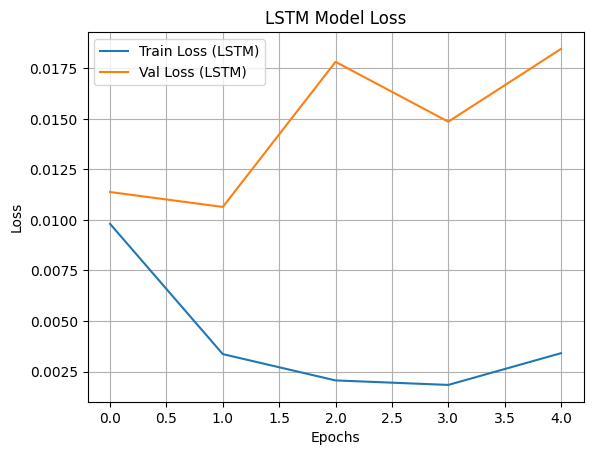

In [12]:
import matplotlib.pyplot as plt

# Plot LSTM training & validation loss
plt.plot(history_lstm.history['loss'], label='Train Loss (LSTM)')
plt.plot(history_lstm.history['val_loss'], label='Val Loss (LSTM)')
plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

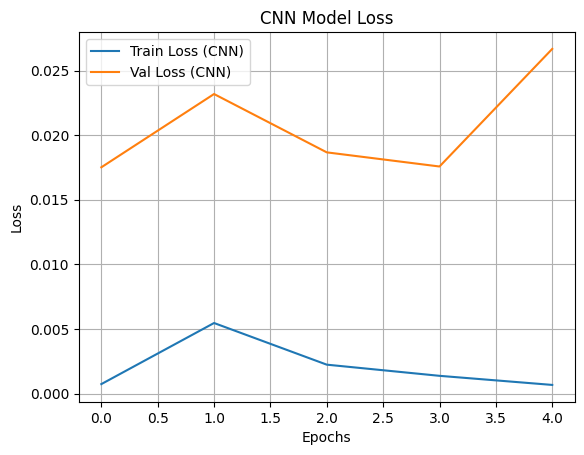

In [13]:
# Plot CNN training & validation loss
plt.plot(history_cnn.history['loss'], label='Train Loss (CNN)')
plt.plot(history_cnn.history['val_loss'], label='Val Loss (CNN)')
plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

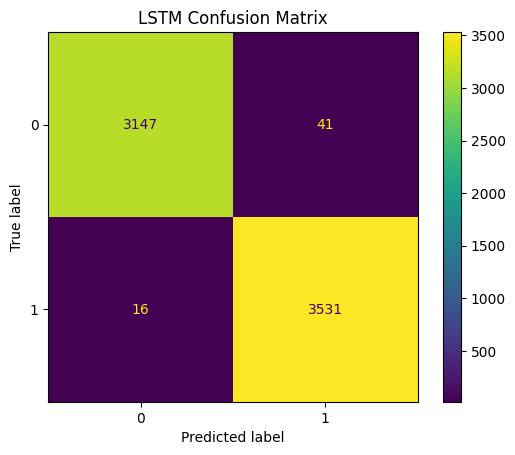

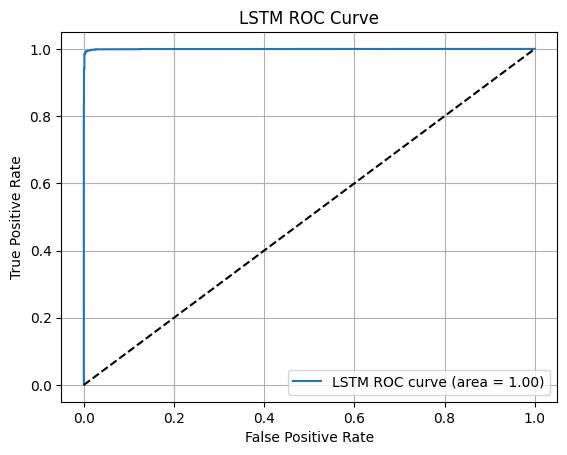

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# Convert probabilities to class labels for LSTM
y_pred_lstm_labels = (y_pred_lstm > 0.5).astype(int)

# Confusion matrix for LSTM
cm_lstm = confusion_matrix(y_test, y_pred_lstm_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lstm)
disp.plot()
plt.title('LSTM Confusion Matrix')
plt.show()

# ROC Curve for LSTM
fpr_lstm, tpr_lstm, _ = roc_curve(y_test, y_pred_lstm)
roc_auc_lstm = auc(fpr_lstm, tpr_lstm)

plt.plot(fpr_lstm, tpr_lstm, label=f'LSTM ROC curve (area = {roc_auc_lstm:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LSTM ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

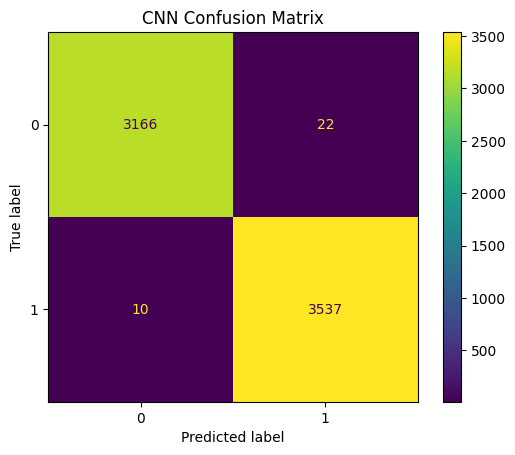

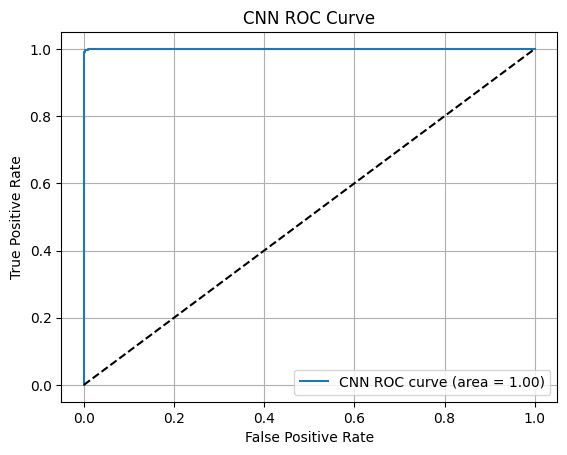

In [16]:
# Convert probabilities to class labels for CNN
y_pred_cnn_labels = (y_pred_cnn > 0.5).astype(int)

# Confusion matrix for CNN
cm_cnn = confusion_matrix(y_test, y_pred_cnn_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_cnn)
disp.plot()
plt.title('CNN Confusion Matrix')
plt.show()

# ROC Curve for CNN
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_pred_cnn)
roc_auc_cnn = auc(fpr_cnn, tpr_cnn)

plt.plot(fpr_cnn, tpr_cnn, label=f'CNN ROC curve (area = {roc_auc_cnn:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('CNN ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
X_test_texts = ["<news article text not available>"] * len(X_test)

X_test_texts is not defined. Using placeholder text instead.


In [19]:
import pandas as pd
import numpy as np

# Assuming X_test_texts contains the original text of the news articles (pre-tokenization)
# Truncate long texts for readability
text_samples = [text[:100] + "..." if len(text) > 100 else text for text in X_test_texts]

# Convert LSTM predictions to binary
y_pred_lstm_labels = (y_pred_lstm > 0.5).astype(int)

# Create a DataFrame showing actual vs predicted
df_lstm_pred = pd.DataFrame({
    "News Text": text_samples,
    "Actual Label": y_test,
    "Predicted Label (LSTM)": y_pred_lstm_labels.flatten()
})

df_lstm_pred.head(10)

,News Text,Actual Label,Predicted Label (LSTM)
20589,<news article text not available>,1,1
35061,<news article text not available>,1,1
21046,<news article text not available>,0,0
36577,<news article text not available>,0,0
41701,<news article text not available>,1,1
22206,<news article text not available>,0,0
19858,<news article text not available>,0,0
4563,<news article text not available>,0,0
42472,<news article text not available>,0,0
25793,<news article text not available>,1,1


In [20]:
# Convert CNN predictions to binary
y_pred_cnn_labels = (y_pred_cnn > 0.5).astype(int)

# Create a DataFrame showing actual vs predicted
df_cnn_pred = pd.DataFrame({
    "News Text": text_samples,
    "Actual Label": y_test,
    "Predicted Label (CNN)": y_pred_cnn_labels.flatten()
})

df_cnn_pred.head(10)


,News Text,Actual Label,Predicted Label (CNN)
20589,<news article text not available>,1,1
35061,<news article text not available>,1,1
21046,<news article text not available>,0,0
36577,<news article text not available>,0,0
41701,<news article text not available>,1,1
22206,<news article text not available>,0,0
19858,<news article text not available>,0,0
4563,<news article text not available>,0,0
42472,<news article text not available>,0,0
25793,<news article text not available>,1,1


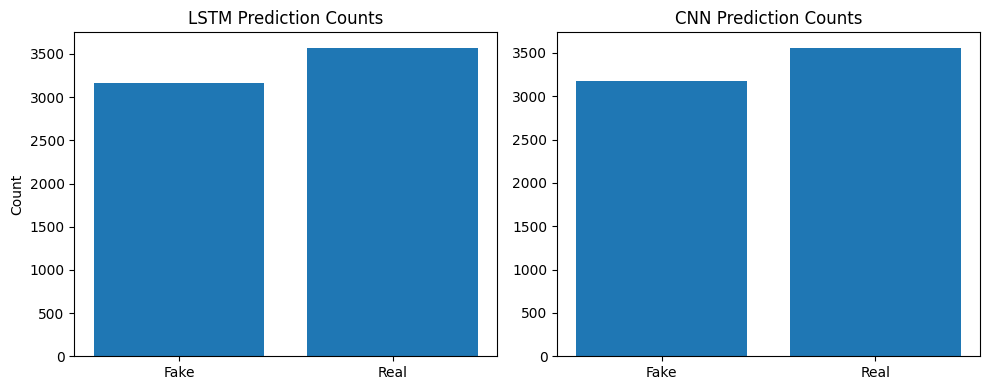

In [21]:
import matplotlib.pyplot as plt

# Count predictions
counts_lstm = pd.Series(y_pred_lstm_labels.flatten()).value_counts().sort_index()
counts_cnn = pd.Series(y_pred_cnn_labels.flatten()).value_counts().sort_index()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].bar(['Fake', 'Real'], counts_lstm)
axs[0].set_title('LSTM Prediction Counts')
axs[0].set_ylabel('Count')

axs[1].bar(['Fake', 'Real'], counts_cnn)
axs[1].set_title('CNN Prediction Counts')

plt.tight_layout()
plt.show()